# Classroom Attention Detection with YOLOv8

In this project we trained an object detection model to look at a classroom photo and label each student as one of:

- `focused`: looking at the screen or the board
- `phone`: using their phone
- `sleeping`: head down or eyes closed
- `looking_away`: looking to the side, behind, or talking to someone
- `empty_seat`: a seat with nobody in it

We took the photos ourselves, labeled them in Roboflow, and trained YOLOv8 on them. At the end we use the model to give each photo an overall attention score.



## 1. Setup

In [4]:
!pip install -q ultralytics

In [5]:
import torch
print("GPU available:", torch.cuda.is_available())

GPU available: True


## 2. Load the dataset

The dataset is submitted with this notebook as a zip file exported from Roboflow in YOLOv8 format. It has `train`, `valid` and `test` folders, each with `images` and `labels`.

To run the notebook, put the zip file in the same folder as the notebook. In Colab, drag it into the Files panel on the left. If your file has a different name, change `DATASET_ZIP` below.

In [6]:
import os, glob, zipfile

DATASET_ZIP = "CV_Attention_detection.zip"
DATASET_DIR = "dataset"

if not os.path.exists(DATASET_DIR):
    with zipfile.ZipFile(DATASET_ZIP) as z:
        z.extractall(DATASET_DIR)

# Roboflow sometimes puts everything inside one extra folder, so we look for data.yaml
yaml_file = glob.glob(f"{DATASET_DIR}/**/data.yaml", recursive=True)[0]
DATASET_DIR = os.path.dirname(os.path.abspath(yaml_file))
print("Dataset folder:", DATASET_DIR)

Dataset folder: /content/dataset


The `data.yaml` file that Roboflow exports uses relative paths that don't always work outside Roboflow. We rewrite it with the correct paths so training works on any machine.

In [7]:
import yaml

cfg = yaml.safe_load(open(f"{DATASET_DIR}/data.yaml"))
names = cfg["names"]

data_config = {
    "path": DATASET_DIR,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(names),
    "names": names,
}

DATA_YAML = f"{DATASET_DIR}/data_local.yaml"
with open(DATA_YAML, "w") as f:
    yaml.dump(data_config, f)

print(open(DATA_YAML).read())

names:
- empty_seat
- focused
- looking_away
- phone
- sleeping
nc: 5
path: /content/dataset
test: test/images
train: train/images
val: valid/images



## 3. A look at the data

In [8]:
for split in ["train", "valid", "test"]:
    n = len(glob.glob(f"{DATASET_DIR}/{split}/images/*"))
    print(f"{split:6s}: {n} images")

train : 144 images
valid : 13 images
test  : 7 images


Number of labeled boxes per class in the training set. The training images were augmented 3x in Roboflow (flip, brightness, blur), so these counts are about three times the original numbers.

In [9]:
from collections import Counter

counts = Counter()
for f in glob.glob(f"{DATASET_DIR}/train/labels/*.txt"):
    for line in open(f):
        if line.strip():
            counts[names[int(line.split()[0])]] += 1

for cls, n in counts.most_common():
    print(f"{cls:14s} {n}")

looking_away   162
focused        78
phone          75
sleeping       48
empty_seat     18


Some training images with their labels drawn on them, to check the annotations look right.

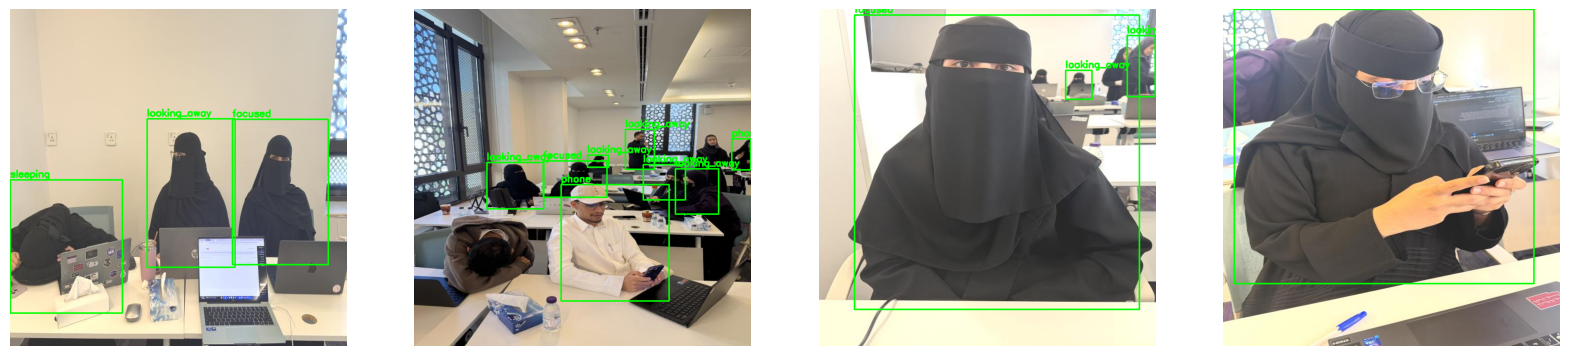

In [10]:
import cv2, random
import matplotlib.pyplot as plt

def show_labeled(img_path, ax):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    label_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    for line in open(label_path):
        c, xc, yc, bw, bh = map(float, line.split())
        # YOLO labels are normalized (0 to 1), so we convert back to pixels
        x1, y1 = int((xc - bw / 2) * w), int((yc - bh / 2) * h)
        x2, y2 = int((xc + bw / 2) * w), int((yc + bh / 2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, names[int(c)], (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    ax.imshow(img[..., ::-1])   # OpenCV loads images as BGR, matplotlib expects RGB
    ax.axis("off")

samples = random.sample(glob.glob(f"{DATASET_DIR}/train/images/*"), 4)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for p, ax in zip(samples, axes):
    show_labeled(p, ax)
plt.show()

## 4. Training

We start from `yolov8n.pt`, the smallest YOLOv8 model, already trained on the COCO dataset. Since COCO includes people, the model already knows what a person looks like, and we only need to teach it our five classes. This is called transfer learning, and it is what makes training possible with a small dataset like ours.

In [11]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data=DATA_YAML,
    epochs=60,
    imgsz=640,
    batch=16,
    name="attention",
    exist_ok=True,
);

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data_local.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0,

## 5. Training loss

YOLO saves the loss for every epoch in `results.csv`. We plot the box loss for training and validation to check that the model is learning and not overfitting.

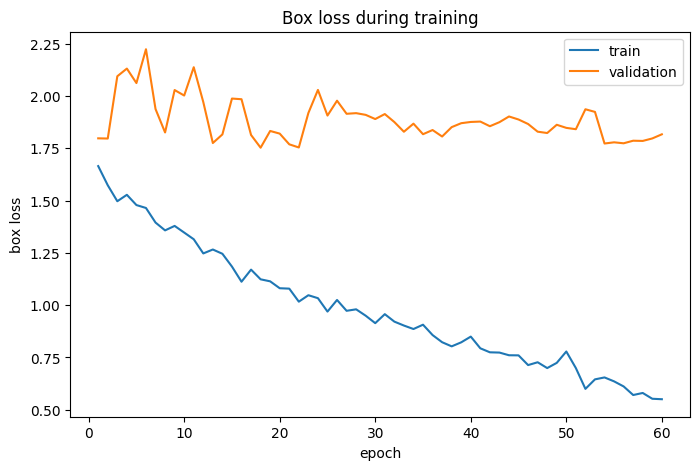

In [12]:
import pandas as pd

RUN = "runs/detect/attention"
history = pd.read_csv(f"{RUN}/results.csv")
history.columns = history.columns.str.strip()

plt.figure(figsize=(8, 5))
plt.plot(history["epoch"], history["train/box_loss"], label="train")
plt.plot(history["epoch"], history["val/box_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("box loss")
plt.title("Box loss during training")
plt.legend()
plt.show()

## 6. Evaluation on the test set

The model never saw the test images during training, so we use them to measure performance.

In detection, every prediction is a box, so before we can compare labels we need to match each predicted box with a real box. We match two boxes if they overlap enough, using IoU (intersection over union) of at least 0.5. After that we have a list of true classes and a list of predicted classes, and we can use the usual sklearn metrics.

- If a real student has no matching prediction, the prediction is `none` (the model missed them).
- If the model predicts a box where there is no real student, the true class is `none` (a false alarm).

In [13]:
best = YOLO(f"{RUN}/weights/best.pt")

def iou(a, b):
    # a and b are boxes as [x1, y1, x2, y2]
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter)

def read_labels(img_path, w, h):
    # convert YOLO labels (normalized center x, y, width, height) to pixel corners
    label_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
    boxes = []
    for line in open(label_path):
        c, xc, yc, bw, bh = map(float, line.split())
        boxes.append((names[int(c)], [(xc - bw/2) * w, (yc - bh/2) * h, (xc + bw/2) * w, (yc + bh/2) * h]))
    return boxes

In [14]:
y_true, y_pred = [], []
test_imgs = glob.glob(f"{DATASET_DIR}/test/images/*")

for p in test_imgs:
    r = best(p, conf=0.4, verbose=False)[0]
    h, w = r.orig_shape
    real = read_labels(p, w, h)
    preds = [(names[int(c)], box.tolist()) for c, box in zip(r.boxes.cls, r.boxes.xyxy)]

    used = set()
    for true_cls, true_box in real:
        # find the predicted box that overlaps this real box the most
        best_iou, best_j = 0, None
        for j, (_, pred_box) in enumerate(preds):
            score = iou(true_box, pred_box)
            if j not in used and score > best_iou:
                best_iou, best_j = score, j

        if best_iou >= 0.5:
            used.add(best_j)
            y_true.append(true_cls)
            y_pred.append(preds[best_j][0])
        else:
            y_true.append(true_cls)
            y_pred.append("none")       # missed

    for j, (pred_cls, _) in enumerate(preds):
        if j not in used:
            y_true.append("none")        # false alarm
            y_pred.append(pred_cls)

print("Real students in test set:", sum(t != "none" for t in y_true))

Real students in test set: 35


In [15]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, zero_division=0))

              precision    recall  f1-score   support

  empty_seat       0.00      0.00      0.00         0
     focused       0.50      0.50      0.50         6
looking_away       0.77      0.53      0.62        19
        none       0.00      0.00      0.00         4
       phone       0.57      0.80      0.67         5
    sleeping       0.75      0.60      0.67         5

    accuracy                           0.51        39
   macro avg       0.43      0.40      0.41        39
weighted avg       0.62      0.51      0.55        39



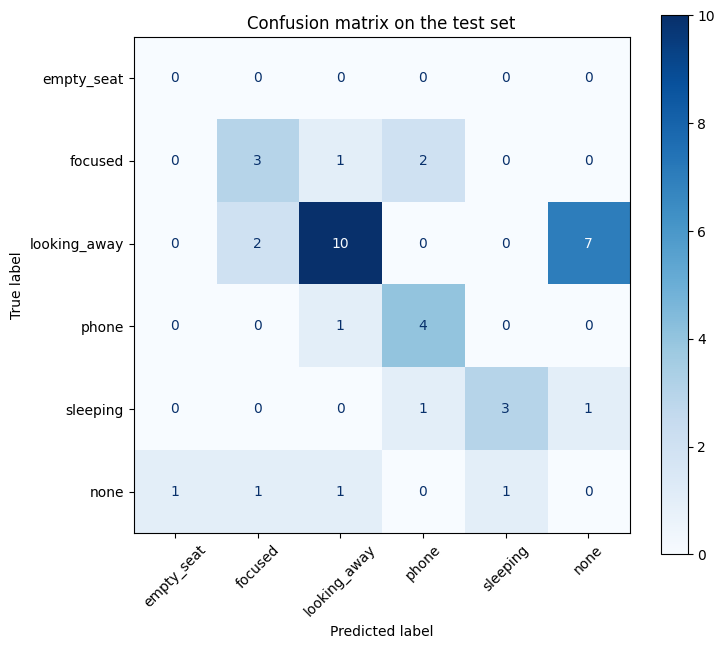

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = list(names) + ["none"]
cm = confusion_matrix(y_true, y_pred, labels=labels)

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Confusion matrix on the test set")
plt.show()

## 7. Predictions on test images

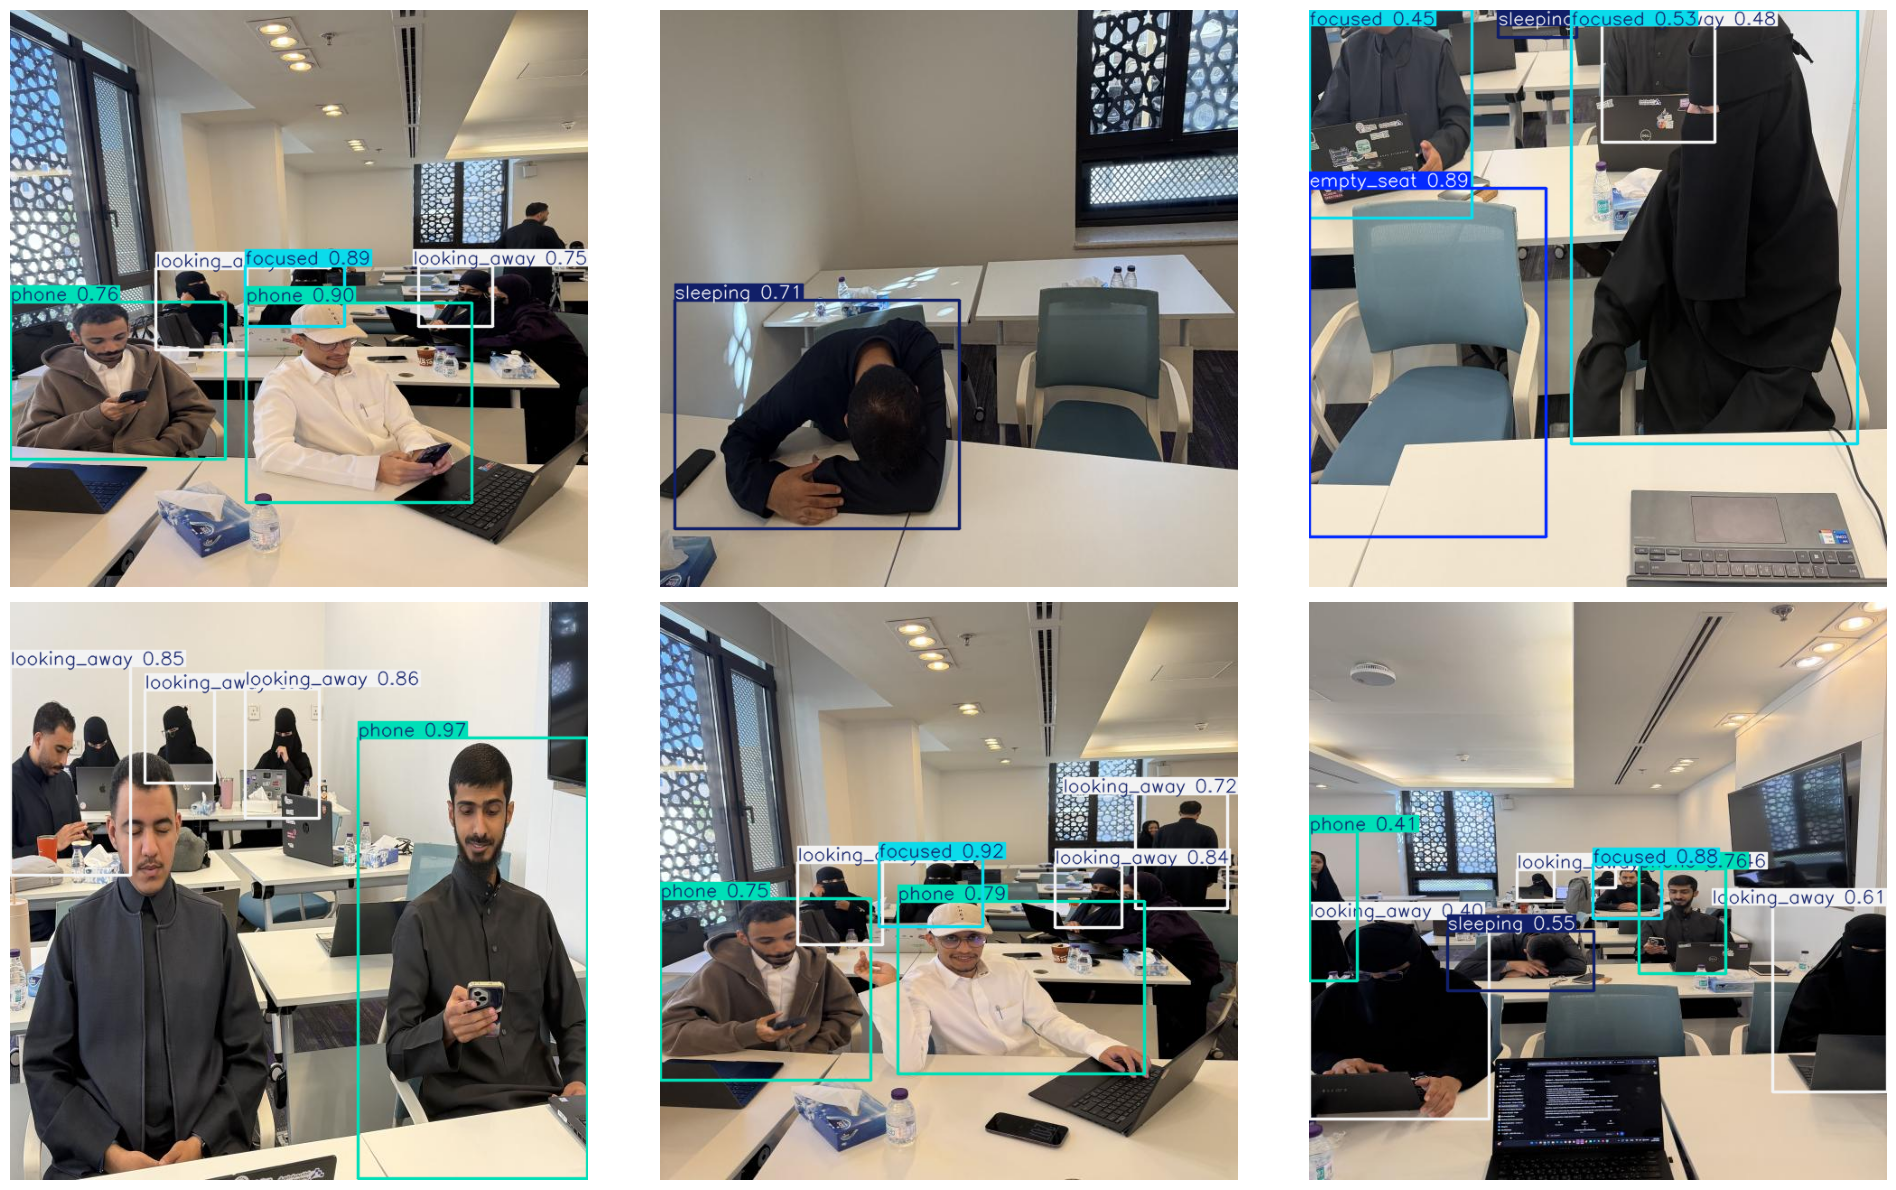

In [17]:
test_imgs = glob.glob(f"{DATASET_DIR}/test/images/*")

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for p, ax in zip(test_imgs, axes.flat):
    r = best(p, conf=0.4, verbose=False)[0]
    ax.imshow(r.plot()[..., ::-1])   # plot() returns BGR, flip to RGB for matplotlib
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Class attention score

This is how the model would be used in practice. For each photo we count the students in each state and calculate:

attention score = focused students / students present

Empty seats are counted as absent, so they don't lower the score.

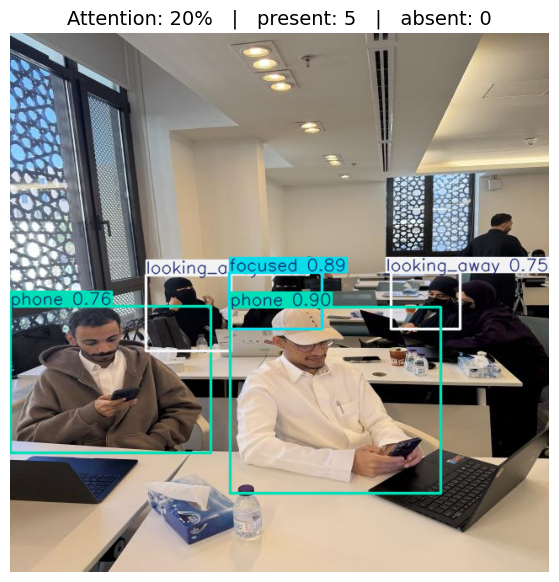

{'phone': 2, 'focused': 1, 'looking_away': 2}


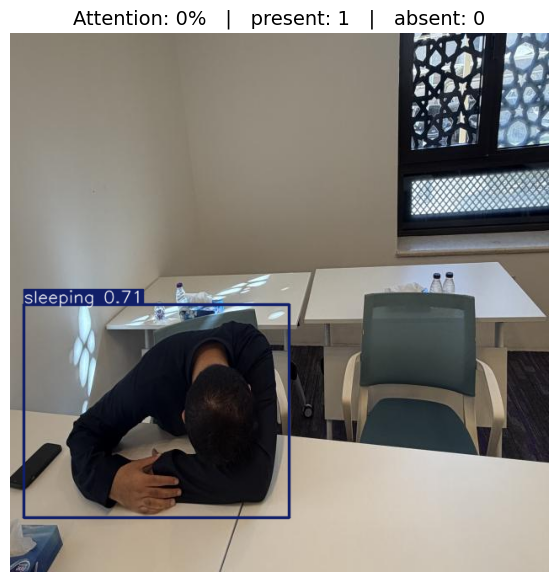

{'sleeping': 1}


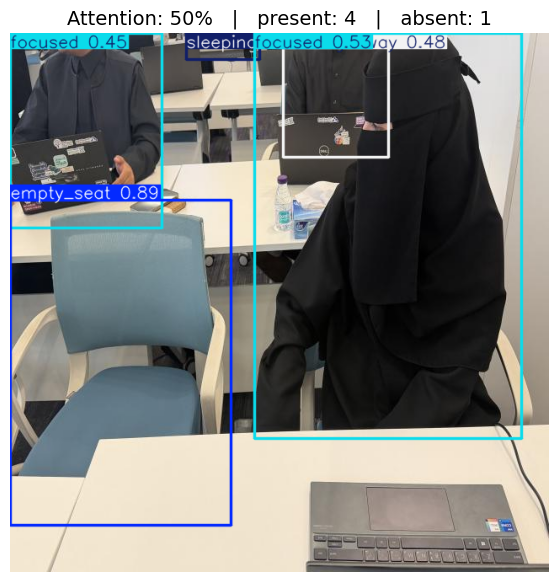

{'empty_seat': 1, 'focused': 2, 'sleeping': 1, 'looking_away': 1}


In [18]:
def attention_report(img_path, conf=0.4):
    r = best(img_path, conf=conf, verbose=False)[0]
    labels = [r.names[int(c)] for c in r.boxes.cls]
    counts = Counter(labels)

    absent = counts.get("empty_seat", 0)
    present = len(labels) - absent
    focused = counts.get("focused", 0)
    score = focused / present * 100 if present else 0

    plt.figure(figsize=(10, 7))
    plt.imshow(r.plot()[..., ::-1])
    plt.axis("off")
    plt.title(f"Attention: {score:.0f}%   |   present: {present}   |   absent: {absent}", fontsize=14)
    plt.show()
    print(dict(counts))

for p in test_imgs[:3]:
    attention_report(p)

To try the model on another photo, put the image next to the notebook, write its name below and run the cell.

In [19]:
MY_IMAGE = None   # for example: "my_class.jpg"

if MY_IMAGE:
    attention_report(MY_IMAGE)

## 9. Results and observations

**Data:** 68 photos that we took ourselves, split into 48 train, 13 validation and 7 test. Roboflow augmented the training set 3x with horizontal flip, brightness changes of up to 20% and a light blur, giving 144 training images. We did not use rotation, because a tilted person can look like they are sleeping.

**Model:** YOLOv8n, 60 epochs, image size 640.

**Test results (from the classification report):**

| Class | Precision | Recall | F1 | Students in test set |
|---|---|---|---|---|
| focused | 0.50 | 0.50 | 0.50 | 6 |
| looking_away | 0.77 | 0.53 | 0.62 | 19 |
| phone | 0.57 | 0.80 | 0.67 | 5 |
| sleeping | 0.75 | 0.60 | 0.67 | 5 |
| **weighted avg** | 0.62 | 0.51 | 0.55 | |

Out of the 35 students in the test photos, the model labeled 20 correctly, gave the wrong label to 7, and missed 8 completely. It also made 4 false alarms, drawing boxes where there was no student.

**What we noticed:**

- `phone` and `sleeping` were the easiest classes (F1 0.67 each). A phone in someone's hand or a head down on the desk is easy to see.
- `focused` was the hardest (F1 0.50). Of the 6 focused students, 2 were labeled as `phone` and 1 as `looking_away`. These states can look very similar in a single photo, for example someone looking down at a notebook can look like someone looking at a phone.
- Most of the missed students were `looking_away` (7 out of 19). This is also why its recall is low even though its precision is the highest.
- The loss plot shows the training loss going down steadily while the validation loss stays around the same level. This means the model is starting to memorize the training images instead of learning patterns that work on new photos. With only 48 original training photos this is expected, and more data is the main fix.
- The classes are not balanced. `looking_away` has about twice as many examples as the other classes.
- `empty_seat` only had 8 examples and none of them ended up in the test set, so we can't measure it. The one time the model predicted it on the test set, it was a false alarm.
- The test set is very small (7 photos), so one easy or hard photo moves the numbers a lot.

**What could improve it:** more photos, especially for `focused` and `empty_seat`, a more balanced number of examples per class, and trying a bigger model like YOLOv8s.

